# Chapitre 7 - Exercices 7.5 à 7.8

Ce notebook traite les exercices sur le write skew et la sérialisabilité :

- **7.5** : un atelier à places limitées ; quand `SELECT ... FOR UPDATE` suffit-il, et
  comment matérialiser le conflit ?
- **7.6** : graphes de précédence, et preuve expérimentale que 2PL ne produit que des
  exécutions sérialisables ;
- **7.7** : dimensionner une base à exécution en série partitionnée ;
- **7.8** : 2PL contre SSI selon la part de transactions en lecture seule (mini-lab).

In [1]:
import itertools

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import (R, W, S, SFU, RFU, INC, run, plot_history, plot_precedence,
                               precedence_graph, is_serializable, simulate_load, LEVEL_LABELS)
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## Exercice 7.5 : un atelier à places limitées

**Énoncé.** Un atelier accepte au plus 3 inscrits. L'inscription compte les inscrits
(`SELECT ... WHERE atelier = 7`), puis insère une ligne si le compte est inférieur à 3.

1. Sous snapshot isolation, combien d'inscrits peut-on obtenir au pire si 4 personnes
   s'inscrivent simultanément alors que l'atelier est vide ?
2. On ajoute `FOR UPDATE` à la requête de comptage, en *read committed*. Montrer que cela
   suffit quand il y a déjà au moins un inscrit, mais pas quand l'atelier est vide.
   Expliquer.
3. Proposer une matérialisation du conflit et la vérifier.

**Rappels.** Write skew, fantômes, `FOR UPDATE` et matérialisation des conflits (cours 3,
sections 7 à 9 ; sections *Phantoms causing write skew* et *Materializing conflicts*).

**Solution.**

*1.* Les 4 transactions comptent 0 dans leur instantané et insèrent chacune une ligne
différente : **4 inscrits**, quel que soit le nombre de places. Avec $n$ inscriptions
simultanées, on peut atteindre $n$ inscrits.

*2.* `FOR UPDATE` verrouille les lignes **trouvées**. S'il y a déjà un inscrit, toutes
les transactions trouvent sa ligne et veulent la verrouiller : elles passent une par une
(la seconde attend la première ; en *read committed*, elle relit ensuite la dernière
version validée et recompte). Si l'atelier est vide, la requête ne trouve rien, aucun
verrou n'est pris : c'est le fantôme. (Subtilité : même avec un inscrit, le compte relu
après l'attente n'inclut la nouvelle ligne que si le moteur réévalue la requête ; notre
moteur, comme PostgreSQL en *read committed*, relit seulement les lignes verrouillées,
d'où l'intérêt de vérifier expérimentalement.)

*3.* On matérialise une ligne `atelier:7` (un compteur de places) que toute inscription
verrouille (`SELECT ... FOR UPDATE` puis incrément) : le conflit porte alors sur une ligne
qui existe toujours. Encore mieux : un incrément conditionnel atomique.

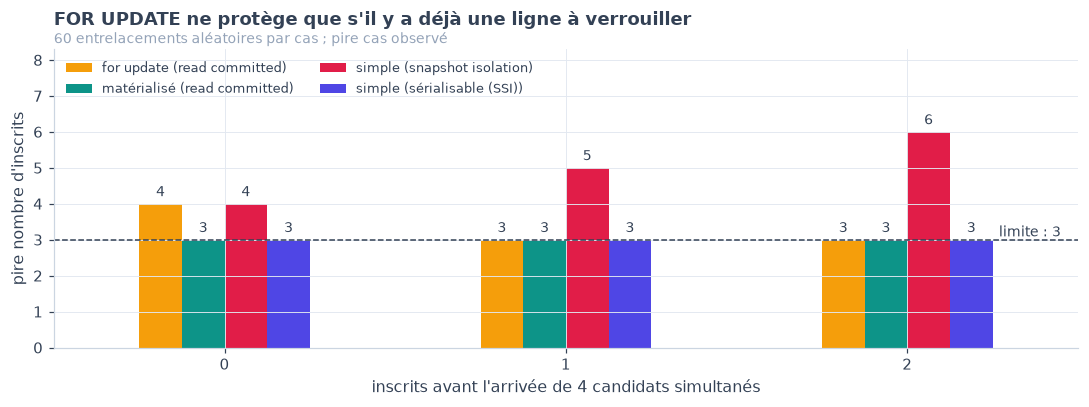

déjà_inscrits,0,1,2
stratégie,,,
for update (read committed),4,3,3
matérialisé (read committed),3,3,3
simple (snapshot isolation),4,5,6
simple (sérialisable (SSI)),3,3,3


In [2]:
atelier7 = lambda k, v: k.startswith("ins:")


def inscription(qui, for_update=False, materialise=False):
    def prog():
        if materialise:
            n = yield RFU("atelier:7")
            if n < 3:
                yield W("atelier:7", n + 1)
                yield W(f"ins:{qui}", True)
            return
        req = SFU(atelier7, "compte") if for_update else S(atelier7, "compte")
        ins = yield req
        if len(ins) < 3:
            yield W(f"ins:{qui}", True)
    return prog


def experience(n_deja, mode, level, n_cand=4, essais=60, seed=0):
    g = np.random.default_rng(seed)
    pire = 0
    for _ in range(essais):
        init = {f"ins:ancien{i}": True for i in range(n_deja)}
        init["atelier:7"] = n_deja
        progs = {f"c{i}": inscription(f"c{i}", mode == "for update", mode == "matérialisé") for i in range(n_cand)}
        ordre = list(g.permutation([f"c{i}" for i in range(n_cand) for _ in range(4)]))
        r = run(init, progs, ordre, level=level)
        pire = max(pire, sum(1 for k in r.final if k.startswith("ins:")))
    return pire


lignes = []
for n_deja in [0, 1, 2]:
    for mode, level in [("simple", "snapshot"), ("for update", "read_committed"), ("matérialisé", "read_committed"),
                        ("simple", "serializable_ssi")]:
        lignes.append(dict(déjà_inscrits=n_deja, stratégie=f"{mode} ({LEVEL_LABELS[level]})",
                           pire_nombre_d_inscrits=experience(n_deja, mode, level)))
tab = pd.DataFrame(lignes).pivot(index="stratégie", columns="déjà_inscrits", values="pire_nombre_d_inscrits")
ax = tab.T.plot.bar(figsize=(10, 3.8), color=[AMBER, TEAL, ROSE, INDIGO], rot=0)
ax.set_ylim(0, 8.3)
ax.axhline(3, color=SLATE, ls="--", lw=1)
ax.text(2.45, 3.1, "limite : 3", fontsize=9, color=SLATE, ha="right")
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("inscrits avant l'arrivée de 4 candidats simultanés")
ax.set_ylabel("pire nombre d'inscrits")
ax.set_title("FOR UPDATE ne protège que s'il y a déjà une ligne à verrouiller")
subtitle(ax, "60 entrelacements aléatoires par cas ; pire cas observé")
ax.legend(fontsize=8.5, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()
tab

Les mesures confirment l'analyse : sans protection, 4 candidats donnent jusqu'à 4 + (déjà
inscrits) lignes ; `FOR UPDATE` dépasse la limite quand l'atelier est vide (aucun verrou
posé), et fonctionne dès qu'une ligne existe ; la matérialisation (verrou sur la ligne
`atelier:7`) et SSI respectent toujours la limite.

> **À retenir.** `FOR UPDATE` protège une décision fondée sur des lignes **qui existent** ;
> une décision fondée sur une **absence** exige un verrou de prédicat (sérialisable) ou
> une ligne matérialisée.